# Segmentación de proveedores con K-Means

**Proyecto BI – Purchasing (AdventureWorks2025)**  
**Responsable de las tareas 3.2.x y 3.3.x:** Molina

| HU | Task | Contenido | Sección |
|---|---|---|---|
| 3.2 | 3.2.1 | Evaluar el número de clusters con el método del codo | Task 3.2.1 |
| 3.2 | 3.2.2 | Calcular el coeficiente de silhouette | Task 3.2.2 |
| 3.2 | 3.2.3 | Entrenar y ejecutar K-Means con la configuración elegida | Task 3.2.3 |
| 3.2 | 3.2.4 | Perfilar los clusters e interpretar sus características | Task 3.2.4 |
| 3.2 | 3.2.5 | Generar la tabla final de proveedores con su segmento | Task 3.2.5 |
| 3.3 | 3.3.1 | Evaluar si los grupos justifican Micro, Pequeñas, Medianas y Grandes | Task 3.3.1 |
| 3.3 | 3.3.2 | Documentar características y limitaciones de cada segmento | Task 3.3.2 |

Este notebook **continúa** el trabajo de `03_preparacion_variables_HU3_1.ipynb`. No repite la
selección ni la transformación de variables: parte de los archivos que ese notebook generó en
`data/processed/`:

- `purchasing_clustering_final.csv`: 88 proveedores con las variables del modelo ya transformadas y escaladas.
- `scaler_clustering.joblib`: el `StandardScaler` ajustado, necesario para volver a unidades originales.

Las variables de entrada del modelo son las columnas escaladas **`ValorTotalOrdenes_z`** (tamaño en
monto) y **`NumeroOrdenes_z`** (actividad o frecuencia de compra).

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)

import warnings; warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path("..") if Path("../data").exists() else Path(".")
PROC = ROOT / "data/processed"

BASE = pd.read_csv(PROC / "purchasing_clustering_final.csv")
ART = joblib.load(PROC / "scaler_clustering.joblib")
SCALER = ART["scaler"]
COLS_MODELO = ART["columnas_modelo"]
TRANSFORMAR_LOG = ART["transformar_log"]

# Matriz de entrada de K-Means: las variables del modelo ya escaladas.
FEATURES = ["ValorTotalOrdenes_z", "NumeroOrdenes_z"]
X = BASE[FEATURES].to_numpy()
RANDOM_STATE = 42

assert BASE[FEATURES].notna().all().all(), "Hay nulos en la matriz del modelo"
assert len(BASE) == 88, f"Se esperaban 88 proveedores y hay {len(BASE)}"

print(f"Proveedores del modelo        : {len(BASE)}")
print(f"Variables de entrada          : {FEATURES}")
print(f"Columnas usadas por el scaler : {COLS_MODELO}")
print(f"Variable con log1p            : {TRANSFORMAR_LOG}")
print("\nPrimeras filas del dataset de entrada:")
display(BASE[["VendorID", "NombreProveedor", *FEATURES]].head())

Proveedores del modelo        : 88
Variables de entrada          : ['ValorTotalOrdenes_z', 'NumeroOrdenes_z']
Columnas usadas por el scaler : ['ValorTotalOrdenes_log', 'NumeroOrdenes']
Variable con log1p            : ['ValorTotalOrdenes']

Primeras filas del dataset de entrada:


,VendorID,NombreProveedor,ValorTotalOrdenes_z,NumeroOrdenes_z
0,1492,Australia Bike Retailer,-0.56,0.56
1,1494,Allenson Cycles,0.52,0.36
2,1496,Advanced Bicycles,-0.61,0.36
3,1498,"Trikes, Inc.",0.95,0.29
4,1500,Morgan Bike Accessories,-0.69,0.29


## 1. Datos de entrada

La población son los **88 proveedores con al menos una orden de compra** (los 18 proveedores sin
órdenes se excluyeron en el EDA y en HU 3.1 porque no tienen monto ni frecuencia que segmentar).

Las dos variables describen dimensiones distintas del proveedor:

- `ValorTotalOrdenes` — **tamaño**: cuánto dinero se le compró en total. Es muy asimétrica, por lo que
  se usó `log1p` antes de escalar (columna `ValorTotalOrdenes_z`).
- `NumeroOrdenes` — **actividad**: cuántas órdenes se le hicieron. Se escaló directamente
  (columna `NumeroOrdenes_z`).

El **método** de esta historia de usuario es:

1. Calcular la inercia para varios valores de `k` y aplicar el **método del codo** (Task 3.2.1).
2. Calcular el **coeficiente de silhouette** para distintos `k` (Task 3.2.2).
3. Elegir `k`, **entrenar K-Means** y asignar cada proveedor a un cluster (Task 3.2.3).
4. **Perfilar** los clusters en unidades originales e **interpretarlos** (Task 3.2.4).
5. Generar la **tabla final** de proveedores con su segmento (Task 3.2.5).
6. **Evaluar** si los grupos equivalen a Micro / Pequeñas / Medianas / Grandes (Task 3.3.1).
7. **Documentar** las características y limitaciones de cada segmento (Task 3.3.2).

##  Evaluar el número de clusters con el método del codo

El **método del codo** entrena K-Means con distintos `k` y observa la **inercia** (suma de las
distancias al cuadrado de cada punto a su centroide, también llamada `WCSS`). La inercia siempre baja al
aumentar `k` (con `k = n` sería 0), así que se busca el punto donde la mejora deja de ser sustancial:
ese cambio de pendiente es el **codo**.

Se evalúa `k` de 1 a 10 y se calcula:

- la **reducción porcentual** de la inercia respecto al `k` anterior, y
- el **punto de máxima curvatura** (la mayor distancia perpendicular a la recta que une el primer y el
  último punto), que identifica el codo de forma automática y no solo visual.

In [2]:
inercias = {}
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=25, random_state=RANDOM_STATE).fit(X)
    inercias[k] = km.inertia_

tabla_codo = pd.DataFrame({"k": list(inercias), "Inercia (WCSS)": list(inercias.values())})
tabla_codo["Reducción (%)"] = tabla_codo["Inercia (WCSS)"].pct_change().mul(-100)
tabla_codo["Reducción acumulada (%)"] = (1 - tabla_codo["Inercia (WCSS)"] / tabla_codo["Inercia (WCSS)"].iloc[0]) * 100
display(tabla_codo)


def punto_codo(ks, valores):
    # Codo = punto de mayor distancia a la recta que une los extremos.
    ks = np.asarray(ks, dtype=float)
    valores = np.asarray(valores, dtype=float)
    x = (ks - ks.min()) / (ks.max() - ks.min())
    y = (valores - valores.min()) / (valores.max() - valores.min())
    x1, y1, x2, y2 = x[0], y[0], x[-1], y[-1]
    dist = np.abs((y2 - y1) * x - (x2 - x1) * y + x2 * y1 - y2 * x1) / np.hypot(y2 - y1, x2 - x1)
    return int(ks[np.argmax(dist)])


K_CODO = punto_codo(tabla_codo["k"], tabla_codo["Inercia (WCSS)"])
print(f"Codo detectado automáticamente (máxima curvatura) en k = {K_CODO}")

,k,Inercia (WCSS),Reducción (%),Reducción acumulada (%)
0,1,176.00,NaN,0.00
1,2,81.89,53.47,53.47
2,3,28.17,65.59,83.99
3,4,13.09,53.56,92.57
4,5,8.92,31.84,94.93
5,6,6.00,32.73,96.59
6,7,3.18,47.04,98.19
7,8,2.40,24.60,98.64
8,9,1.86,22.43,98.94
9,10,1.41,23.99,99.20


Codo detectado automáticamente (máxima curvatura) en k = 3


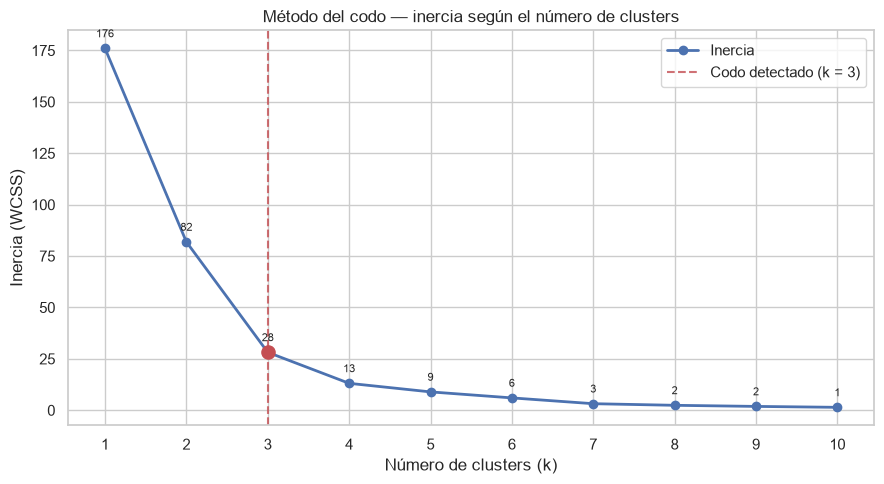

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tabla_codo["k"], tabla_codo["Inercia (WCSS)"], "o-", color="#4C72B0", lw=2, label="Inercia")
ax.axvline(K_CODO, color="#C44E52", ls="--", alpha=0.8, label=f"Codo detectado (k = {K_CODO})")
ax.scatter([K_CODO], [inercias[K_CODO]], color="#C44E52", s=90, zorder=5)

for k in tabla_codo["k"]:
    ax.annotate(f"{inercias[k]:,.0f}", (k, inercias[k]), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8)

ax.set_title("Método del codo — inercia según el número de clusters")
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inercia (WCSS)")
ax.set_xticks(list(tabla_codo["k"]))
ax.legend()
plt.tight_layout()
plt.show()

**Lectura (Task 3.2.1).** La inercia cae de forma muy pronunciada hasta `k = 3` y a partir de ahí las
mejoras son cada vez menores:

| k | Inercia | Reducción respecto al k anterior |
|---|---|---|
| 2 | 81.89 | −49.6 % |
| 3 | 28.17 | −65.6 % |
| 4 | 13.09 | −53.5 % |
| 5 | 8.92 | −31.9 % |

El codo automático (máxima curvatura) queda en **`k = 3`**. El codo, por sí solo, admite también `k = 4`
como candidato, así que la decisión no se cierra todavía: se contrasta con el coeficiente de silhouette
en la siguiente tarea.

## Calcular el coeficiente de silhouette para evaluar la separación de los grupos

El **coeficiente de silhouette** mide, para cada proveedor, qué tan bien encaja en su propio cluster
frente al cluster vecino más cercano. Va de **−1 a 1**:

- **cerca de 1**: el punto está muy bien asignado y los grupos están separados.
- **cerca de 0**: el punto está en la frontera entre dos grupos.
- **negativo**: el punto podría estar mejor en otro cluster.

Se calcula:

- el **silhouette promedio** para `k` de 2 a 10 (para comparar configuraciones),
- el silhouette **por cluster** y **por muestra** para los mejores candidatos, y
- dos índices complementarios: **Davies-Bouldin** (más bajo = mejor) y **Calinski-Harabasz** (más alto = mejor).

In [4]:
filas = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=25, random_state=RANDOM_STATE).fit(X)
    filas.append({
        "k": k,
        "Inercia": km.inertia_,
        "Silhouette": silhouette_score(X, km.labels_),
        "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
        "Calinski-Harabasz": calinski_harabasz_score(X, km.labels_),
        "Mín. proveedores/cluster": int(np.bincount(km.labels_).min()),
        "Máx. proveedores/cluster": int(np.bincount(km.labels_).max()),
    })

metricas = pd.DataFrame(filas).set_index("k")
K_SIL = int(metricas["Silhouette"].idxmax())
print(f"Máximo silhouette promedio en k = {K_SIL} ({metricas.loc[K_SIL, 'Silhouette']:.4f})")
display(metricas)

Máximo silhouette promedio en k = 4 (0.7384)


,Inercia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Mín. proveedores/cluster,Máx. proveedores/cluster
k,,,,,,
2,81.89,0.71,0.59,98.84,9,79
3,28.17,0.72,0.43,222.99,9,40
4,13.09,0.74,0.32,348.60,2,40
5,8.92,0.70,0.36,388.72,2,39
6,6.00,0.70,0.37,464.68,2,39
7,3.18,0.67,0.39,734.23,2,29
8,2.40,0.68,0.37,828.04,2,29
9,1.86,0.68,0.32,925.23,1,29
10,1.41,0.63,0.37,"1,071.08",1,20


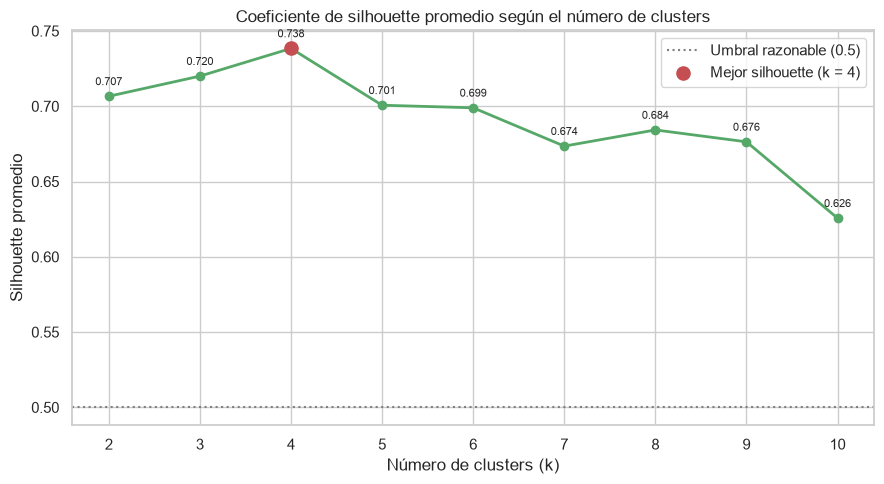

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(metricas.index, metricas["Silhouette"], "o-", color="#55A868", lw=2)
ax.axhline(0.5, color="grey", ls=":", label="Umbral razonable (0.5)")
best = metricas["Silhouette"].idxmax()
ax.scatter([best], [metricas.loc[best, "Silhouette"]], color="#C44E52", s=90, zorder=5,
           label=f"Mejor silhouette (k = {best})")
for k in metricas.index:
    ax.annotate(f"{metricas.loc[k, 'Silhouette']:.3f}", (k, metricas.loc[k, "Silhouette"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_title("Coeficiente de silhouette promedio según el número de clusters")
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Silhouette promedio")
ax.set_xticks(list(metricas.index))
ax.legend()
plt.tight_layout()
plt.show()

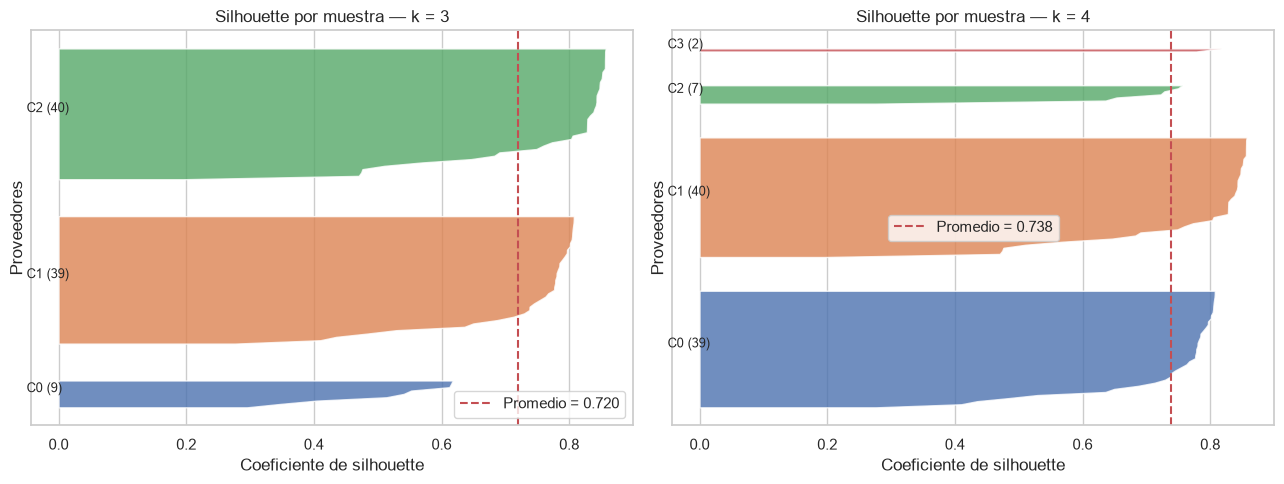

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, k in zip(axes, [3, 4]):
    km = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(X)
    sil = silhouette_samples(X, km.labels_)
    y_lower = 10
    for c in range(k):
        vals = np.sort(sil[km.labels_ == c])
        y_upper = y_lower + vals.shape[0]
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.8)
        ax.text(-0.05, y_lower + 0.5 * vals.shape[0], f"C{c} ({vals.shape[0]})", fontsize=9)
        y_lower = y_upper + 10
    ax.axvline(silhouette_score(X, km.labels_), color="#C44E52", ls="--",
               label=f"Promedio = {silhouette_score(X, km.labels_):.3f}")
    ax.set_title(f"Silhouette por muestra — k = {k}")
    ax.set_xlabel("Coeficiente de silhouette")
    ax.set_ylabel("Proveedores")
    ax.set_yticks([])
    ax.legend()
plt.tight_layout()
plt.show()

**Lectura (Task 3.2.2).** Todos los valores de silhouette son altos (por encima de 0.62), lo que indica
grupos bien separados. El máximo cae en **`k = 4` (0.738)** y muy cerca queda **`k = 3` (0.720)`**;
`k = 2` da 0.707.

Sin embargo, la diferencia entre `k = 3` y `k = 4` es pequeña (≈ 0.018) y el cluster extra de `k = 4`
agrupa a **solo 2 proveedores** (los de montos más pequeños), es decir, aísla un caso extremo más que
describir un grupo de negocio. Los índices complementarios (Davies-Bouldin y Calinski-Harabasz) también
favorecen valores algo mayores, pero la métrica no es concluyente por sí sola. La decisión se cierra en
la Task 3.2.3 combinando codo, silhouette, tamaño de los grupos e interpretabilidad.

## Entrenar y ejecutar K-Means con la configuración seleccionada

Se comparan los dos candidatos principales (`k = 3` y `k = 4`) con las métricas y el tamaño de sus
clusters. Criterios de decisión:

1. **Codo** → apunta a `k = 3`.
2. **Silhouette** → `k = 4` (0.738) supera a `k = 3` (0.720) por muy poco.
3. **Tamaño de los grupos** → `k = 4` genera un cluster de **2 proveedores**, que no es un segmento de
   negocio robusto ni interpretable.
4. **Parsimonia** → a igualdad razonable de métricas, se prefiere la solución más simple.

In [7]:
comparacion = metricas.loc[[2, 3, 4, 5],
                           ["Inercia", "Silhouette", "Davies-Bouldin",
                            "Calinski-Harabasz", "Mín. proveedores/cluster"]]
display(comparacion)

tam3 = np.bincount(KMeans(n_clusters=3, n_init=50, random_state=RANDOM_STATE).fit(X).labels_)
tam4 = np.bincount(KMeans(n_clusters=4, n_init=50, random_state=RANDOM_STATE).fit(X).labels_)

print(f"Tamaño de los clusters con k=3: {sorted(tam3.tolist(), reverse=True)}")
print(f"Tamaño de los clusters con k=4: {sorted(tam4.tolist(), reverse=True)}")
print()
print("Decisión: k = 3.")
print("- El codo está en k=3.")
print("- El silhouette de k=4 solo mejora 0.018 y a cambio crea un cluster de 2 proveedores (2.3%).")
print("- k=3 produce tres grupos de tamaño razonable y con lectura de negocio clara.")

,Inercia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Mín. proveedores/cluster
k,,,,,
2,81.89,0.71,0.59,98.84,9
3,28.17,0.72,0.43,222.99,9
4,13.09,0.74,0.32,348.60,2
5,8.92,0.70,0.36,388.72,2


Tamaño de los clusters con k=3: [40, 39, 9]
Tamaño de los clusters con k=4: [40, 39, 7, 2]

Decisión: k = 3.
- El codo está en k=3.
- El silhouette de k=4 solo mejora 0.018 y a cambio crea un cluster de 2 proveedores (2.3%).
- k=3 produce tres grupos de tamaño razonable y con lectura de negocio clara.


In [8]:
K_FINAL = 3
modelo_final = KMeans(n_clusters=K_FINAL, n_init=50, random_state=RANDOM_STATE).fit(X)
BASE["Cluster"] = modelo_final.labels_

print(f"K-Means entrenado con k = {K_FINAL}, n_init = 50, random_state = {RANDOM_STATE}.")
print(f"Inercia           : {modelo_final.inertia_:,.2f}")
print(f"Silhouette        : {silhouette_score(X, BASE['Cluster']):.4f}")
print(f"Davies-Bouldin    : {davies_bouldin_score(X, BASE['Cluster']):.4f}")
print(f"Calinski-Harabasz : {calinski_harabasz_score(X, BASE['Cluster']):,.2f}")
print("\nReparto de proveedores por cluster:")
display(BASE["Cluster"].value_counts().sort_index().rename("Proveedores").to_frame().assign(
    **{"% proveedores": lambda d: d["Proveedores"] / len(BASE) * 100}))

K-Means entrenado con k = 3, n_init = 50, random_state = 42.
Inercia           : 28.17
Silhouette        : 0.7200
Davies-Bouldin    : 0.4336
Calinski-Harabasz : 222.99

Reparto de proveedores por cluster:


,Proveedores,% proveedores
Cluster,,
0,9,10.23
1,39,44.32
2,40,45.45


**Conclusión (Task 3.2.3).** Se selecciona **`k = 3`**. El modelo se entrena con
`KMeans(n_clusters=3, n_init=50, random_state=42)` sobre las 88 observaciones y las dos variables
escaladas. Cada proveedor queda etiquetado con su cluster.

## Perfilar los clusters e interpretar sus características

Los centroides viven en el espacio escalado y **no son interpretables directamente**. Para perfilarlos:

1. Se usa el `scaler` guardado para llevar los centroides a la escala del modelo
   (`ValorTotalOrdenes_log` y `NumeroOrdenes`) con `inverse_transform`.
2. Se revierte la transformación logarítmica con `np.expm1` para recuperar el **monto en unidades
   originales** (pesos/dólares).
3. Se calcula el perfil de cada cluster a partir de los proveedores que lo componen.

In [9]:
centroides_z = pd.DataFrame(modelo_final.cluster_centers_, columns=FEATURES,
                            index=[f"Cluster {i}" for i in range(K_FINAL)])
centroides_orig = pd.DataFrame(SCALER.inverse_transform(modelo_final.cluster_centers_),
                               columns=COLS_MODELO, index=centroides_z.index)
# TRANSFORMAR_LOG guarda el nombre original; la columna del modelo es "<variable>_log".
for col in TRANSFORMAR_LOG:
    log_col = f"{col}_log"
    if log_col in centroides_orig.columns:
        centroides_orig[log_col] = np.expm1(centroides_orig[log_col])
        centroides_orig = centroides_orig.rename(columns={log_col: col})

print("Centroides en el espacio escalado (z):")
display(centroides_z)
print("Centroides en unidades originales (media de cada cluster):")
display(centroides_orig)

Centroides en el espacio escalado (z):


,ValorTotalOrdenes_z,NumeroOrdenes_z
Cluster 0,-0.79,-2.96
Cluster 1,-0.74,0.34
Cluster 2,0.90,0.34


Centroides en unidades originales (media de cada cluster):


,ValorTotalOrdenes,NumeroOrdenes
Cluster 0,"17,899.44",1.78
Cluster 1,"20,177.59",50.64
Cluster 2,"1,311,770.55",50.70


In [10]:
perfil = BASE.groupby("Cluster").agg(
    Proveedores=("VendorID", "size"),
    Monto_medio=("ValorTotalOrdenes", "mean"),
    Monto_mediano=("ValorTotalOrdenes", "median"),
    Monto_min=("ValorTotalOrdenes", "min"),
    Monto_max=("ValorTotalOrdenes", "max"),
    Monto_total=("ValorTotalOrdenes", "sum"),
    Ordenes_medio=("NumeroOrdenes", "mean"),
    Ordenes_min=("NumeroOrdenes", "min"),
    Ordenes_max=("NumeroOrdenes", "max"),
)
perfil["% proveedores"] = perfil["Proveedores"] / len(BASE) * 100
perfil["% del monto total"] = perfil["Monto_total"] / BASE["ValorTotalOrdenes"].sum() * 100
perfil = perfil.sort_values("Monto_medio", ascending=False)
display(perfil)

,Proveedores,Monto_medio,Monto_mediano,Monto_min,Monto_max,Monto_total,Ordenes_medio,Ordenes_min,Ordenes_max,% proveedores,% del monto total
Cluster,,,,,,,,,,,
2,40,"1,673,732.96","1,591,939.29","209,264.43","5,034,266.74","66,949,318.31",50.70,50.00,51.00,45.45,94.98
0,9,"264,541.43","42,658.00",17.00,"1,186,835.76","2,380,872.91",1.78,1.00,4.00,10.23,3.38
1,39,"29,647.19","25,732.84","2,048.42","112,931.19","1,156,240.47",50.64,50.00,54.00,44.32,1.64


In [11]:
# --- Etiquetado de los segmentos a partir del perfil (no está fijado de antemano) ---
cluster_ocasional = perfil["Ordenes_medio"].idxmin()
restantes = [c for c in perfil.index if c != cluster_ocasional]
cluster_grande = perfil.loc[restantes, "Monto_medio"].idxmax()
cluster_pequeno = perfil.loc[restantes, "Monto_medio"].idxmin()

NOMBRES = {
    cluster_grande: "Grandes recurrentes",
    cluster_pequeno: "Pequeños recurrentes",
    cluster_ocasional: "Ocasionales",
}
# Fallback de seguridad si el cluster de menor actividad no fuera el más heterogéneo
assert len(set(NOMBRES.values())) == K_FINAL, "Etiquetas repetidas"

BASE["Segmento"] = BASE["Cluster"].map(NOMBRES)
perfil.insert(0, "Segmento", perfil.index.map(NOMBRES))

print("Etiquetado resultante:")
display(pd.DataFrame({"Cluster": list(NOMBRES), "Segmento": [NOMBRES[k] for k in NOMBRES]}))
display(perfil[["Segmento", "Proveedores", "% proveedores", "% del monto total",
                "Monto_mediano", "Ordenes_medio"]])

Etiquetado resultante:


,Cluster,Segmento
0,2,Grandes recurrentes
1,1,Pequeños recurrentes
2,0,Ocasionales


,Segmento,Proveedores,% proveedores,% del monto total,Monto_mediano,Ordenes_medio
Cluster,,,,,,
2,Grandes recurrentes,40,45.45,94.98,"1,591,939.29",50.70
0,Ocasionales,9,10.23,3.38,"42,658.00",1.78
1,Pequeños recurrentes,39,44.32,1.64,"25,732.84",50.64


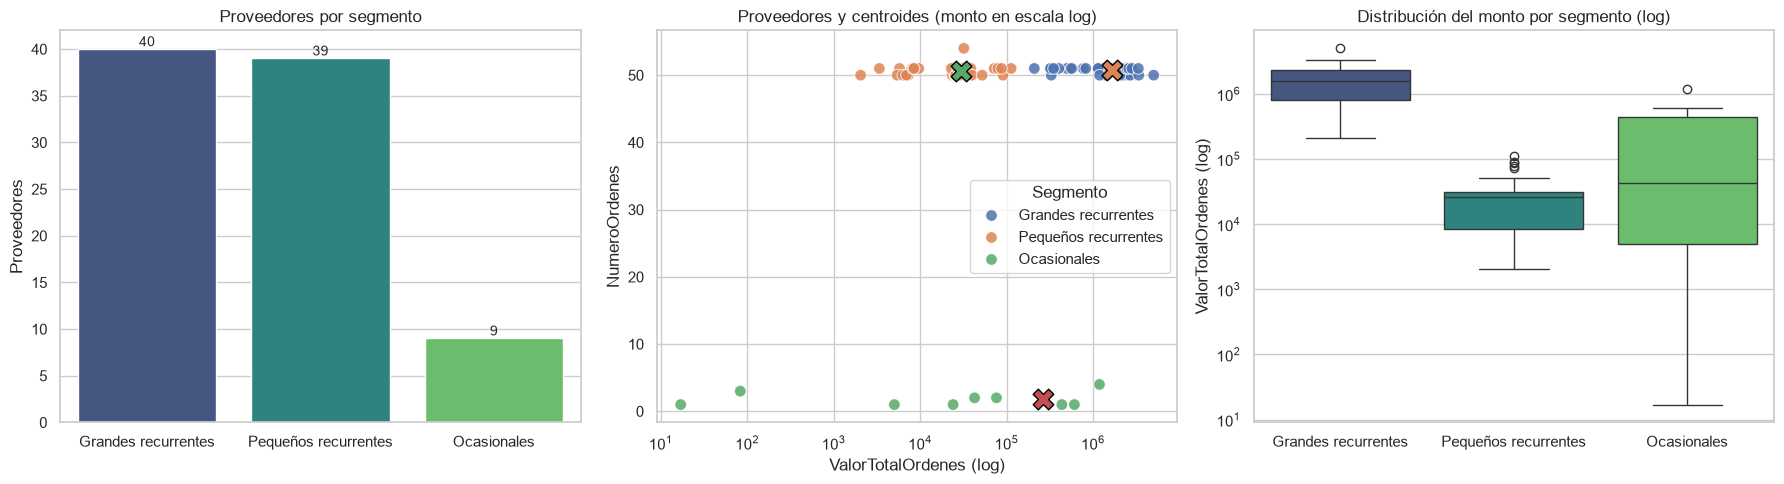

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Tamaño de cada segmento
orden_seg = ["Grandes recurrentes", "Pequeños recurrentes", "Ocasionales"]
conteo = BASE["Segmento"].value_counts().reindex(orden_seg)
sns.barplot(x=conteo.index, y=conteo.values, ax=axes[0], palette="viridis")
axes[0].set_title("Proveedores por segmento")
axes[0].set_ylabel("Proveedores")
axes[0].set_xlabel("")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontsize=10)

# 2) Dispersión en unidades originales (monto en escala log)
sns.scatterplot(data=BASE, x="ValorTotalOrdenes", y="NumeroOrdenes", hue="Segmento",
                hue_order=orden_seg, ax=axes[1], s=70, alpha=0.85)
axes[1].set_xscale("log")
axes[1].set_title("Proveedores y centroides (monto en escala log)")
axes[1].set_xlabel("ValorTotalOrdenes (log)")
axes[1].set_ylabel("NumeroOrdenes")
centros = perfil.reset_index().set_index("Segmento").reindex(orden_seg)
for seg in orden_seg:
    axes[1].scatter(centros.loc[seg, "Monto_medio"], centros.loc[seg, "Ordenes_medio"],
                    marker="X", s=220, edgecolor="black", zorder=5)

# 3) Boxplot del monto por segmento
sns.boxplot(data=BASE, x="Segmento", y="ValorTotalOrdenes", order=orden_seg, ax=axes[2],
            palette="viridis")
axes[2].set_yscale("log")
axes[2].set_title("Distribución del monto por segmento (log)")
axes[2].set_xlabel("")
axes[2].set_ylabel("ValorTotalOrdenes (log)")

plt.tight_layout()
plt.show()

In [13]:
print(f"PERFIL DE LOS {K_FINAL} SEGMENTOS — {len(BASE)} proveedores\n")
for seg in ["Grandes recurrentes", "Pequeños recurrentes", "Ocasionales"]:
    fila = perfil[perfil["Segmento"] == seg].iloc[0]
    print(f"• {seg}: {int(fila['Proveedores'])} proveedores "
          f"({fila['% proveedores']:.1f} %), {fila['% del monto total']:.1f} % del monto total.")
    print(f"    Monto: mediana {fila['Monto_mediano']:,.0f} "
          f"[{fila['Monto_min']:,.0f} – {fila['Monto_max']:,.0f}] | "
          f"Órdenes: media {fila['Ordenes_medio']:.1f} "
          f"[{fila['Ordenes_min']:.0f} – {fila['Ordenes_max']:.0f}].")

PERFIL DE LOS 3 SEGMENTOS — 88 proveedores

• Grandes recurrentes: 40 proveedores (45.5 %), 95.0 % del monto total.
    Monto: mediana 1,591,939 [209,264 – 5,034,267] | Órdenes: media 50.7 [50 – 51].
• Pequeños recurrentes: 39 proveedores (44.3 %), 1.6 % del monto total.
    Monto: mediana 25,733 [2,048 – 112,931] | Órdenes: media 50.6 [50 – 54].
• Ocasionales: 9 proveedores (10.2 %), 3.4 % del monto total.
    Monto: mediana 42,658 [17 – 1,186,836] | Órdenes: media 1.8 [1 – 4].


**Interpretación (Task 3.2.4).** La estructura que encuentra K-Means combina **frecuencia** y **monto**:

- **Grandes recurrentes** — proveedores con muchas órdenes (≈ 51) y montos altos (mediana ≈ 1.59 M;
  máximo ≈ 5.03 M). Son el grupo que concentra la mayor parte del gasto. Agrupa a proveedores muy
  activos y de alto valor.
- **Pequeños recurrentes** — también con muchas órdenes (≈ 51), pero montos bajos (mediana ≈ 25.7 k).
  Son compras frecuentes de bajo valor: proveedores de insumos o repuestos menores.
- **Ocasionales** — pocas órdenes (entre 1 y 4) y montos muy dispares (de 17 a ≈ 1.19 M). No se
  caracterizan por el monto sino por la **baja frecuencia**; una compra puntual puede ser grande o
  pequeña.

La separación no es una simple escala de tamaño: los dos primeros segmentos se distinguen por el
**monto**, y el tercero por la **frecuencia**. Eso explica por qué en `k = 4` aparece un cuarto grupo
diminuto (2 proveedores) al partir el segmento de menor monto en su extremo.

##  Generar la tabla final de proveedores con su segmento asignado

Se construye la tabla final a nivel de proveedor, con su identificador, nombre, las variables que
definen el segmento y las etiquetas de **cluster** (número) y **segmento** (nombre). Se guarda en
`data/processed/purchasing_segmentos_kmeans.csv`.

In [14]:
COLS_FINALES = ["VendorID", "NombreProveedor", "ValorTotalOrdenes", "NumeroOrdenes",
                "Cluster", "Segmento"]

tabla_final = (BASE[COLS_FINALES]
               .sort_values(["Segmento", "ValorTotalOrdenes"], ascending=[True, False])
               .reset_index(drop=True))

ruta = PROC / "purchasing_segmentos_kmeans.csv"
tabla_final.to_csv(ruta, index=False, encoding="utf-8-sig")

print(f"Tabla final: {tabla_final.shape[0]} proveedores × {tabla_final.shape[1]} columnas")
print(f"Guardada en: {ruta}\n")
print("Composición por segmento:")
display(tabla_final["Segmento"].value_counts().rename("Proveedores").to_frame())
print("\nPrimeras filas:")
display(tabla_final.head(10))

Tabla final: 88 proveedores × 6 columnas
Guardada en: ..\data\processed\purchasing_segmentos_kmeans.csv

Composición por segmento:


,Proveedores
Segmento,
Grandes recurrentes,40
Pequeños recurrentes,39
Ocasionales,9



Primeras filas:


,VendorID,NombreProveedor,ValorTotalOrdenes,NumeroOrdenes,Cluster,Segmento
0,1576,Superior Bicycles,"5,034,266.74",50.00,2,Grandes recurrentes
1,1684,Professional Athletic Consultants,"3,379,946.32",50.00,2,Grandes recurrentes
2,1696,Chicago City Saddles,"3,347,165.20",51.00,2,Grandes recurrentes
3,1680,Jackson Authority,"2,821,333.52",51.00,2,Grandes recurrentes
4,1578,"Vision Cycles, Inc.","2,777,684.91",50.00,2,Grandes recurrentes
5,1632,Sport Fan Co.,"2,675,889.22",50.00,2,Grandes recurrentes
6,1678,"Proseware, Inc.","2,593,901.31",51.00,2,Grandes recurrentes
7,1506,Greenwood Athletic Company,"2,472,770.05",51.00,2,Grandes recurrentes
8,1658,Crowley Sport,"2,472,770.05",51.00,2,Grandes recurrentes
9,1586,Mitchell Sports,"2,424,284.37",50.00,2,Grandes recurrentes


**Producto (Task 3.2.5).** `purchasing_segmentos_kmeans.csv` contiene una fila por proveedor con:

| Columna | Descripción |
|---|---|
| `VendorID` | Identificador del proveedor. |
| `NombreProveedor` | Nombre del proveedor. |
| `ValorTotalOrdenes` | Monto total comprado (unidades originales). |
| `NumeroOrdenes` | Cantidad de órdenes de compra. |
| `Cluster` | Número de cluster asignado por K-Means (0, 1, 2). |
| `Segmento` | Etiqueta legible del segmento. |

La tabla puede unirse por `VendorID` con el consolidado (`purchasing_consolidated.csv`) para enriquecer
el análisis con las demás variables del proveedor.

## ¿Los grupos justifican Micro, Pequeñas, Medianas y Grandes? 

La idea de negocio original era etiquetar a los proveedores en cuatro categorías ordenadas por tamaño
(Micro, Pequeñas, Medianas y Grandes), una escala clásica de clasificación por actividad. Aquí se
evalúa si el clustering **realmente** produce esos cuatro niveles.

Se contrasta de dos maneras:

1. **¿Aporta `k = 4` cuatro niveles ordenados por tamaño?** Se perfilan los clusters de `k = 4` y se
   comprueba si quedan ordenados de menor a mayor monto.
2. **Relación con cortes de negocio.** Se parte el monto en **cuartiles** (Micro/Pequeña/Mediana/Grande)
   y se compara con los segmentos mediante una tabla cruzada y el índice **ARI** (Adjusted Rand Index).

In [15]:
km4 = KMeans(n_clusters=4, n_init=50, random_state=RANDOM_STATE).fit(X)
perfil4 = BASE.assign(C4=km4.labels_).groupby("C4").agg(
    Proveedores=("VendorID", "size"),
    Monto_mediano=("ValorTotalOrdenes", "median"),
    Monto_medio=("ValorTotalOrdenes", "mean"),
    Ordenes_medio=("NumeroOrdenes", "mean"),
).sort_values("Monto_mediano")

print("Perfil de los clusters con k = 4 (ordenados por monto mediano):")
display(perfil4)
print(f"¿Los 4 grupos quedan ordenados por tamaño? "
      f"{'Sí' if perfil4['Monto_mediano'].is_monotonic_increasing else 'No'}")
print(f"Cluster más pequeño de k=4: {int(perfil4['Proveedores'].min())} proveedores "
      f"({perfil4['Proveedores'].min() / len(BASE) * 100:.1f} %).")

Perfil de los clusters con k = 4 (ordenados por monto mediano):


,Proveedores,Monto_mediano,Monto_medio,Ordenes_medio
C4,,,,
3,2,50.05,50.05,2.00
0,39,"25,732.84","29,647.19",50.64
2,7,"76,348.25","340,110.40",1.71
1,40,"1,591,939.29","1,673,732.96",50.70


¿Los 4 grupos quedan ordenados por tamaño? Sí
Cluster más pequeño de k=4: 2 proveedores (2.3 %).


In [16]:
categorias = pd.qcut(BASE["ValorTotalOrdenes"], 4,
                     labels=["Micro", "Pequeña", "Mediana", "Grande"], duplicates="drop")
BASE["Categoria_monto"] = categorias

ct = pd.crosstab(BASE["Segmento"], BASE["Categoria_monto"])
print("Tabla cruzada: segmento K-Means (filas) vs. cuartil de monto (columnas)")
display(ct)

ari = adjusted_rand_score(BASE["Categoria_monto"].astype(str), BASE["Segmento"])
print(f"Adjusted Rand Index entre categorías de monto y segmentos: {ari:.3f}")
print("ARI = 1 significa coincidencia perfecta; 0, coincidencia por azar.")

Tabla cruzada: segmento K-Means (filas) vs. cuartil de monto (columnas)


Categoria_monto,Micro,Pequeña,Mediana,Grande
Segmento,,,,
Grandes recurrentes,0,0,18,22
Ocasionales,4,2,3,0
Pequeños recurrentes,18,20,1,0


Adjusted Rand Index entre categorías de monto y segmentos: 0.418
ARI = 1 significa coincidencia perfecta; 0, coincidencia por azar.


In [17]:
# ¿Los cuartiles de monto coinciden con las órdenes? (para ver si el tamaño explica la frecuencia)
print("Comportamiento de la frecuencia (NumeroOrdenes) por cuartil de monto:")
display(BASE.groupby("Categoria_monto", observed=True)["NumeroOrdenes"].agg(
    ["count", "mean", "min", "max"]))

Comportamiento de la frecuencia (NumeroOrdenes) por cuartil de monto:


,count,mean,min,max
Categoria_monto,,,,
Micro,22,41.59,1.00,51.00
Pequeña,22,46.32,2.00,54.00
Mediana,22,44.14,1.00,51.00
Grande,22,50.64,50.00,51.00


**Conclusión (Task 3.3.1).** Los grupos **no justifican** las cuatro categorías ordenadas
Micro / Pequeñas / Medianas / Grandes, por tres razones:

1. **El número natural de grupos es 3, no 4.** El codo está en `k = 3` y el cuarto grupo de `k = 4`
   solo reúne a **2 proveedores (2.3 %)**, por lo que no representa un nivel de actividad real. Aunque
   con `k = 4` los grupos quedan ordenados por monto mediano, ese cuarto "nivel" es un caso extremo, no
   una categoría de negocio.
2. **La partición no reproduce una escala de tamaño.** El ARI frente a los **cuartiles de monto**
   (Micro/Pequeña/Mediana/Grande) es **0.418**, lejos de 1: proveedores que caen en el mismo cuartil de
   monto aparecen en segmentos distintos según su **frecuencia** de compra. K-Means separa
   bidimensionalmente (**frecuencia** × **monto**), no en cuatro escalones de tamaño.
3. **Los grupos de baja frecuencia son pequeños y heterogéneos.** El segmento "Ocasionales" reúne solo
   a 9 proveedores cuyos montos van de 17 a ≈ 1.19 M; no forman una categoría homogénea de tamaño.

Por tanto, forzar cuatro etiquetas de tamaño sería una decisión de negocio impuesta, no un hallazgo del
modelo. Se propone mantener **tres segmentos** con nombres que reflejan la realidad de los datos. Si el
equipo necesita las cuatro categorías por requisito de negocio, conviene definirlas con **umbrales
acordados sobre el monto** (por ejemplo, los cuartiles) en lugar de con K-Means.

## Características y limitaciones de cada segmento

Se resume cada segmento con su definición operativa, su tamaño, sus rangos y sus limitaciones. La tabla
se guarda en `data/processed/documentacion_segmentos.csv` para dejarla disponible al equipo.

In [18]:
def rango(fila, col):
    return f"{fila[col + '_min']:,.0f} – {fila[col + '_max']:,.0f}"


filas_doc = []
for seg in ["Grandes recurrentes", "Pequeños recurrentes", "Ocasionales"]:
    f = perfil[perfil["Segmento"] == seg].iloc[0]
    if seg == "Grandes recurrentes":
        definicion = "Alta frecuencia y alto monto. Núcleo de compras estratégicas."
        caracteristicas = ("Muchas órdenes (≈51) y montos altos; concentran la mayor parte del gasto. "
                           "Candidatos a negociación de precios y acuerdos marco.")
        limitaciones = ("Pueden incluir órdenes pendientes o valores atípicos que inflan el monto; "
                        "conviene revisar el efecto de Status (pendientes/rechazadas).")
    elif seg == "Pequeños recurrentes":
        definicion = "Alta frecuencia y bajo monto. Compras operativas de bajo valor."
        caracteristicas = ("Muchas órdenes (≈51) pero montos bajos; alta carga administrativa relativa "
                           "al valor comprado.")
        limitaciones = ("Bajo monto agregado; el costo de gestión por orden puede pesar. "
                        "El corte con 'Grandes' depende de la distribución del monto.")
    else:
        definicion = "Baja frecuencia. Compras puntuales o esporádicas."
        caracteristicas = ("Entre 1 y 4 órdenes; montos muy dispares (de decenas a más de un millón). "
                           "Se caracterizan por la frecuencia, no por el monto.")
        limitaciones = ("Grupo heterogéneo en monto: una sola compra grande y varias pequeñas caen juntas. "
                        "Con tan pocas órdenes, el monto es inestable como señal.")
    filas_doc.append({
        "Segmento": seg,
        "Definición": definicion,
        "Proveedores": int(f["Proveedores"]),
        "% proveedores": round(f["% proveedores"], 1),
        "% del monto total": round(f["% del monto total"], 1),
        "Monto mediano": round(f["Monto_mediano"], 0),
        "Rango de monto": rango(f, "Monto"),
        "Rango de órdenes": f"{f['Ordenes_min']:.0f} – {f['Ordenes_max']:.0f}",
        "Características": caracteristicas,
        "Limitaciones": limitaciones,
    })

doc_segmentos = pd.DataFrame(filas_doc)
doc_segmentos.to_csv(PROC / "documentacion_segmentos.csv", index=False, encoding="utf-8-sig")
print("Documentación de segmentos guardada en data/processed/documentacion_segmentos.csv\n")
display(doc_segmentos.set_index("Segmento").T)

Documentación de segmentos guardada en data/processed/documentacion_segmentos.csv



Segmento,Grandes recurrentes,Pequeños recurrentes,Ocasionales
Definición,Alta frecuencia y alto monto. Núcleo de compras estratégicas.,Alta frecuencia y bajo monto. Compras operativas de bajo valor.,Baja frecuencia. Compras puntuales o esporádicas.
Proveedores,40,39,9
% proveedores,45.50,44.30,10.20
% del monto total,95.00,1.60,3.40
Monto mediano,"1,591,939.00","25,733.00","42,658.00"
Rango de monto,"209,264 – 5,034,267","2,048 – 112,931","17 – 1,186,836"
Rango de órdenes,50 – 51,50 – 54,1 – 4
Características,Muchas órdenes (≈51) y montos altos; concentran la mayor parte del gasto. Candidatos a negociación de precios y acuerdos marco.,Muchas órdenes (≈51) pero montos bajos; alta carga administrativa relativa al valor comprado.,"Entre 1 y 4 órdenes; montos muy dispares (de decenas a más de un millón). Se caracterizan por la frecuencia, no por el monto."
Limitaciones,Pueden incluir órdenes pendientes o valores atípicos que inflan el monto; conviene revisar el efecto de Status (pendientes/rechazadas).,Bajo monto agregado; el costo de gestión por orden puede pesar. El corte con 'Grandes' depende de la distribución del monto.,"Grupo heterogéneo en monto: una sola compra grande y varias pequeñas caen juntas. Con tan pocas órdenes, el monto es inestable como señal."


### Limitaciones generales del modelo

1. **Solo dos variables.** El modelo describe **tamaño** (`ValorTotalOrdenes`) y **frecuencia**
   (`NumeroOrdenes`). No incorpora precio unitario, tiempo de entrega, calidad, categoría de producto ni
   ubicación; dos proveedores muy distintos en esos aspectos pueden caer en el mismo segmento.
2. **`NumeroOrdenes` está muy concentrada.** El 88.6 % de los proveedores tiene entre 50 y 54 órdenes;
   solo 9 tienen pocas. Por eso el clustering está dominado por el **monto** y el principal eje de
   separación de la frecuencia es "recurrente vs. ocasional".
3. **Los montos incluyen órdenes pendientes y rechazadas.** El consolidado no filtra por `Status`, así
   que parte del monto puede corresponder a compras no consolidadas. Es una decisión abierta del equipo.
4. **Proveedores sin órdenes excluidos.** Los 18 proveedores sin compras (21 en el consolidado original,
   ver EDA) no tienen monto ni frecuencia y quedan fuera del modelo; no pueden asignarse a un segmento.
5. **Muestra pequeña.** Con 88 observaciones, los clusters muy pequeños (como el de 2 proveedores en
   `k = 4`) son sensibles a cambios de datos; por eso se prefirió `k = 3`.
6. **Las etiquetas son descriptivas.** "Grandes", "Pequeños" y "Ocasionales" son una convención de
   lectura; no provienen de umbrales de negocio validados.

## Conclusiones y próximos pasos

- **Número de clusters:** el codo apunta a `k = 3` y el silhouette máximo a `k = 4` (0.738 vs 0.720).
  Se eligió **`k = 3`** por el codo, el tamaño equilibrado de los grupos y la interpretabilidad;
  `k = 4` solo aportaba un cluster de 2 proveedores.
- **Segmentos obtenidos:**
  - **Grandes recurrentes** — muchas órdenes y montos altos.
  - **Pequeños recurrentes** — muchas órdenes y montos bajos.
  - **Ocasionales** — pocas órdenes y montos heterogéneos.
- **Sobre Micro/Pequeñas/Medianas/Grandes:** los datos **no** justifican una escala de cuatro tamaños;
  la estructura es bidimensional (frecuencia × monto). Se documentan tres segmentos en su lugar.

